# Question 1 — Word Segmentation and POS Tagging

## Objective

This project implements the NLP pipeline required in Group Assignment 1:

1. Word segmentation using a trigram word-level language model and dynamic programming.
2. POS tagging using emission probabilities and trigram tag-transition probabilities.
3. Morphology-aware POS tagging for Spanish using gender and number information.
4. Baseline comparison:
   - Greedy longest-match segmentation
   - Most-frequent-tag POS tagging
5. Evaluation using:
   - Segmentation precision, recall and F1
   - POS tagging accuracy
   - Confusion matrices
   - Segmentation-caused vs genuine POS-tagging errors
6. Required sample test strings and additional examples.

## Languages

- English: Brown Corpus
- Spanish: UD Spanish-GSD

Spanish is used as the morphologically richer language.

In [178]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [179]:
import os

MODEL_DIR = "/content/drive/MyDrive/GROUP_ASSIGNMENT_1/models"

os.makedirs(MODEL_DIR, exist_ok=True)

print("Model directory:", MODEL_DIR)

Model directory: /content/drive/MyDrive/GROUP_ASSIGNMENT_1/models


In [180]:
!pip install -q conllu cloudpickle

import os
import math
import random
import cloudpickle

from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import nltk
from nltk.corpus import brown

nltk.download("brown", quiet=True)
nltk.download("universal_tagset", quiet=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Setup complete.")

Setup complete.


In [181]:
# Clone the Spanish UD corpus only if it is not already present.
if not os.path.exists("UD_Spanish-GSD"):
    !git clone --depth 1 https://github.com/UniversalDependencies/UD_Spanish-GSD.git

from conllu import parse_incr


def load_english_data(seed=42):
    """
    Load Brown Corpus with the Universal POS tagset
    and create an 80/20 train/test split as required.
    """
    sentences = brown.tagged_sents(tagset="universal")

    cleaned = []

    for sent in sentences:
        tokens = []

        for word, tag in sent:
            word = word.lower().strip()

            # Ignore empty/punctuation-only tokens.
            if not word:
                continue

            if all(ch in ".,;:!?\"'()[]{}--" for ch in word):
                continue

            tokens.append((word, tag))

        if len(tokens) >= 3:
            cleaned.append(tokens)

    rng = random.Random(seed)
    rng.shuffle(cleaned)

    split = int(0.8 * len(cleaned))

    train = cleaned[:split]
    test = cleaned[split:]

    return train, test


def load_ud(path):
    """
    Load a UD CoNLL-U file.

    Each token is stored as:
        (word, UPOS, gender, number)

    Multi-word-token rows are skipped.
    Punctuation is excluded because this assignment focuses on
    word segmentation and POS tagging of words.
    """
    sentences = []

    with open(path, encoding="utf-8") as f:
        for token_list in parse_incr(f):

            sent = []

            for tok in token_list:

                # Skip multi-word-token ranges such as 1-2.
                if not isinstance(tok["id"], int):
                    continue

                # Skip punctuation.
                if tok["upos"] == "PUNCT":
                    continue

                word = tok["form"].lower().strip()

                if not word:
                    continue

                feats = tok["feats"] or {}

                gender = feats.get("Gender")
                number = feats.get("Number")

                # Normalize possible multi-valued features.
                if isinstance(gender, list):
                    gender = gender[0]

                if isinstance(number, list):
                    number = number[0]

                sent.append(
                    (word, tok["upos"], gender, number)
                )

            if len(sent) >= 3:
                sentences.append(sent)

    return sentences


# -------------------------
# English
# -------------------------
en_train, en_test = load_english_data(SEED)

print(
    f"English: {len(en_train)} training sentences, "
    f"{len(en_test)} test sentences"
)


# -------------------------
# Spanish
# -------------------------
es_train = load_ud(
    "UD_Spanish-GSD/es_gsd-ud-train.conllu"
)

es_dev = load_ud(
    "UD_Spanish-GSD/es_gsd-ud-dev.conllu"
)

es_test = load_ud(
    "UD_Spanish-GSD/es_gsd-ud-test.conllu"
)

print(
    f"Spanish: {len(es_train)} train, "
    f"{len(es_dev)} dev, "
    f"{len(es_test)} test"
)

print("\nEnglish sample:")
print(en_train[0][:8])

print("\nSpanish sample:")
print(es_train[0][:8])

English: 44060 training sentences, 11015 test sentences
Spanish: 14148 train, 1399 dev, 426 test

English sample:
[('historically', 'ADV'), ('re', 'NOUN'), ('is', 'VERB'), ('the', 'DET'), ('formative', 'NOUN'), ('that', 'PRON'), ('is', 'VERB'), ('employed', 'VERB')]

Spanish sample:
[('además', 'ADV', None, None), ('se', 'PRON', None, None), ('le', 'PRON', None, 'Sing'), ('pediría', 'VERB', None, 'Sing'), ('a', 'ADP', None, None), ('las', 'DET', 'Fem', 'Plur'), ('empresas', 'NOUN', 'Fem', 'Plur'), ('interesadas', 'ADJ', 'Fem', 'Plur')]


In [182]:
class TrigramWordLM:
    """
    Word-level trigram language model for word segmentation.
    Uses dynamic programming (Viterbi) to find the best segmentation.
    """

    def __init__(
        self,
        sentences,
        max_word_len=18,
        lambda3=0.45,
        lambda2=0.25,
        lambda1=0.30,
        lambda0=0.00,
        word_penalty=1.5
    ):
        self.max_word_len = max_word_len

        self.lambda3 = lambda3
        self.lambda2 = lambda2
        self.lambda1 = lambda1
        self.lambda0 = lambda0

        # Penalty applied for every predicted word.
        # This discourages unnecessary splitting.
        self.word_penalty = word_penalty

        # Frequency counts
        self.unigram = Counter()
        self.bigram = Counter()
        self.trigram = Counter()
        self.vocab = set()

        # --------------------------------------------------
        # Build language-model counts
        # --------------------------------------------------
        for sent in sentences:

            # Add two start symbols for trigram context
            words = ["<s>", "<s>"]

            # Add sentence words
            words.extend(
                word
                for word, *_ in sent
            )

            # Add end symbol
            words.append("</s>")

            # Unigram counts
            self.unigram.update(words)

            # Vocabulary
            self.vocab.update(words)

            # Bigram counts
            for i in range(len(words) - 1):
                self.bigram[
                    (words[i], words[i + 1])
                ] += 1

            # Trigram counts
            for i in range(len(words) - 2):
                self.trigram[
                    (
                        words[i],
                        words[i + 1],
                        words[i + 2]
                    )
                ] += 1

        self.total_unigrams = sum(
            self.unigram.values()
        )

        # Remove special sentence symbols from word vocabulary
        self.word_vocab = {
            word
            for word in self.vocab
            if word not in {"<s>", "</s>"}
        }

    # ------------------------------------------------------
    # Interpolated trigram probability
    # ------------------------------------------------------
    def word_probability(self, w1, w2, w3):

        # Trigram probability
        context_12 = self.bigram.get(
            (w1, w2),
            0
        )

        if context_12 > 0:
            p3 = (
                self.trigram.get(
                    (w1, w2, w3),
                    0
                )
                / context_12
            )
        else:
            p3 = 0.0

        # Bigram probability
        context_2 = self.unigram.get(
            w2,
            0
        )

        if context_2 > 0:
            p2 = (
                self.bigram.get(
                    (w2, w3),
                    0
                )
                / context_2
            )
        else:
            p2 = 0.0

        # Unigram probability
        if self.total_unigrams > 0:
            p1 = (
                self.unigram.get(w3, 0)
                / self.total_unigrams
            )
        else:
            p1 = 0.0

        # Interpolated probability
        probability = (
            self.lambda3 * p3
            + self.lambda2 * p2
            + self.lambda1 * p1
            + self.lambda0
        )

        # Avoid log(0)
        return max(
            probability,
            1e-15
        )

    # ------------------------------------------------------
    # Viterbi / Dynamic Programming segmentation
    # ------------------------------------------------------
    def segment(self, text):

        text = text.lower().strip()

        if not text:
            return []

        n = len(text)

        # dp[position][(previous_previous_word, previous_word)]
        #
        # Stores:
        # (
        #     best_score,
        #     previous_position,
        #     previous_previous_word
        # )
        dp = [
            {}
            for _ in range(n + 1)
        ]

        # Initial state
        dp[0][
            ("<s>", "<s>")
        ] = (
            0.0,
            None,
            None
        )

        # --------------------------------------------------
        # Forward dynamic programming
        # --------------------------------------------------
        for end in range(1, n + 1):

            start_min = max(
                0,
                end - self.max_word_len
            )

            for start in range(
                start_min,
                end
            ):

                word = text[start:end]

                # Candidate must be a known vocabulary word
                if word not in self.word_vocab:
                    continue

                # No reachable state
                if not dp[start]:
                    continue

                # Try every previous state
                for (
                    (w1, w2),
                    (
                        previous_score,
                        _,
                        _
                    )
                ) in dp[start].items():

                    probability = self.word_probability(
                        w1,
                        w2,
                        word
                    )

                    # Small reward for longer valid words.
                    # Helps avoid excessive fragmentation.
                    length_bonus = (
                        0.35 * math.log(len(word) + 1)
                    )

                    # Total candidate score
                    score = (
                        previous_score
                        + math.log(probability)
                        - self.word_penalty
                        + length_bonus
                    )

                    # New state
                    state = (
                        w2,
                        word
                    )

                    # Keep the best path reaching this state
                    if (
                        state not in dp[end]
                        or
                        score > dp[end][state][0]
                    ):
                        dp[end][state] = (
                            score,
                            start,
                            w1
                        )

        # --------------------------------------------------
        # If no complete segmentation exists
        # --------------------------------------------------
        if not dp[n]:
            return [text]

        # --------------------------------------------------
        # Include sentence-end probability
        # --------------------------------------------------
        best_state = None
        best_score = -float("inf")

        for (
            (w1, w2),
            (
                score,
                _,
                _
            )
        ) in dp[n].items():

            end_probability = self.word_probability(
                w1,
                w2,
                "</s>"
            )

            final_score = (
                score
                + math.log(end_probability)
            )

            if final_score > best_score:
                best_score = final_score
                best_state = (
                    w1,
                    w2
                )

        # --------------------------------------------------
        # Backtrace
        # --------------------------------------------------
        words = []

        position = n

        w1, w2 = best_state

        while position > 0:

            words.append(w2)

            (
                _score,
                previous_position,
                previous_w1
            ) = dp[position][
                (w1, w2)
            ]

            position = previous_position

            w2 = w1
            w1 = previous_w1

        # Reverse because backtrace gives reverse order
        words.reverse()

        return words

In [183]:
def greedy_longest_match(
    text,
    vocab,
    max_word_len=18
):
    """
    Baseline segmentation method.

    At every position:
        choose the longest vocabulary word possible.
    """

    text = text.lower()

    words = []

    i = 0

    while i < len(text):

        match = None

        max_len = min(
            max_word_len,
            len(text) - i
        )

        for length in range(
            max_len,
            0,
            -1
        ):

            candidate = text[
                i:i + length
            ]

            if candidate in vocab:

                match = candidate

                break

        if match is None:

            # Fallback if no known word exists.
            match = text[i]

        words.append(match)

        i += len(match)

    return words

In [184]:
lm_en = TrigramWordLM(en_train)
lm_es = TrigramWordLM(es_train)

vocab_en = {
    word
    for word in lm_en.vocab
    if word not in {"<s>", "</s>"}
}

vocab_es = {
    word
    for word in lm_es.vocab
    if word not in {"<s>", "</s>"}
}

print(
    "English vocabulary size:",
    len(vocab_en)
)

print(
    "Spanish vocabulary size:",
    len(vocab_es)
)

English vocabulary size: 44963
Spanish vocabulary size: 42186


In [185]:
english_input = (
    "thequickbrownfoxjumpsoverthelazydog"
)

spanish_input_1 = "lacasarojaesgrande"

spanish_input_2 = "mispadrespuedenviajar"

spanish_input_3 = "elcielodespejadoesazul"


print("ENGLISH")
print(
    "Input:",
    english_input
)

print(
    "Trigram:",
    lm_en.segment(english_input)
)

print(
    "Greedy:",
    greedy_longest_match(
        english_input,
        vocab_en
    )
)


print("\nSPANISH")
for text in [
    spanish_input_1,
    spanish_input_2,
    spanish_input_3
]:

    print(
        "\nInput:",
        text
    )

    print(
        "Trigram:",
        lm_es.segment(text)
    )

    print(
        "Greedy:",
        greedy_longest_match(
            text,
            vocab_es
        )
    )

ENGLISH
Input: thequickbrownfoxjumpsoverthelazydog
Trigram: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
Greedy: ['the', 'quick', 'brown', 'fox', 'jumps', 'overt', 'hel', 'a', 'z', 'y', 'dog']

SPANISH

Input: lacasarojaesgrande
Trigram: ['la', 'casa', 'roja', 'es', 'grande']
Greedy: ['la', 'casar', 'oja', 'es', 'grande']

Input: mispadrespuedenviajar
Trigram: ['mis', 'padres', 'pueden', 'viajar']
Greedy: ['mis', 'padres', 'pueden', 'viajar']

Input: elcielodespejadoesazul
Trigram: ['el', 'cielo', 'des', 'pe', 'j', 'ado', 'es', 'azul']
Greedy: ['el', 'cielo', 'des', 'pe', 'j', 'ado', 'esa', 'z', 'ul']


In [186]:
class TrigramHMMTagger:
    """
    Trigram Hidden Markov Model POS tagger.

    Emission:
        P(word | tag)

    Transition:
        P(tag_i | tag_{i-2}, tag_{i-1})

    Decoding:
        Viterbi dynamic programming.
    """

    def __init__(self, tagged_sentences, tag_fn=None):

        self.tag_fn = (
            tag_fn
            if tag_fn is not None
            else lambda item: item[1]
        )

        self.emission = defaultdict(Counter)
        self.tag_count = Counter()

        self.transition = defaultdict(Counter)
        self.transition_context_count = Counter()

        self.word_tag_count = defaultdict(Counter)

        self.tagset = set()

        # ---------------------------------
        # Collect training statistics
        # ---------------------------------

        for sent in tagged_sentences:

            tags = ["<s>", "<s>"]

            tags.extend(
                self.tag_fn(item)
                for item in sent
            )

            tags.append("</s>")

            words = (
                [None, None]
                + [item[0] for item in sent]
                + [None]
            )

            # Emission counts
            for i in range(2, len(tags) - 1):

                word = words[i]
                tag = tags[i]

                self.emission[tag][word] += 1
                self.tag_count[tag] += 1

                self.word_tag_count[word][tag] += 1

                self.tagset.add(tag)

            # Tag trigram counts
            for i in range(len(tags) - 2):

                t1 = tags[i]
                t2 = tags[i + 1]
                t3 = tags[i + 2]

                self.transition[
                    (t1, t2)
                ][t3] += 1

                self.transition_context_count[
                    (t1, t2)
                ] += 1

        self.tagset = sorted(self.tagset)

        self.num_tags = len(self.tagset)

        self.most_common_tag = (
            self.tag_count
            .most_common(1)[0][0]
        )

        self.vocab = set(
            self.word_tag_count.keys()
        )

    def transition_probability(
        self,
        t1,
        t2,
        t3,
        alpha=0.1
    ):
        """
        Smoothed trigram transition:

            P(t3 | t1, t2)
        """

        numerator = (
            self.transition[
                (t1, t2)
            ].get(t3, 0)
            + alpha
        )

        denominator = (
            self.transition_context_count[
                (t1, t2)
            ]
            + alpha * self.num_tags
        )

        return numerator / denominator

    def emission_probability(
        self,
        tag,
        word,
        k=0.05
    ):
        """
        Smoothed emission:

            P(word | tag)

        We smooth using the vocabulary observed
        for the particular tag.
        """

        word_count = (
            self.emission[tag]
            .get(word, 0)
        )

        tag_total = self.tag_count[tag]

        tag_vocab_size = max(
            len(self.emission[tag]),
            1
        )

        return (
            (word_count + k)
            /
            (
                tag_total
                +
                k * tag_vocab_size
            )
        )

    def candidate_tags(
        self,
        word,
        fallback_size=12
    ):
        """
        For a known word:
            consider tags seen with that word.

        For an unseen word:
            consider the most frequent tags.
        """

        if word in self.word_tag_count:

            return list(
                self.word_tag_count[word].keys()
            )

        return [
            tag
            for tag, _ in
            self.tag_count.most_common(
                fallback_size
            )
        ]

    def tag(self, words):
        """
        Viterbi decoding of the POS tag sequence.
        """

        n = len(words)

        if n == 0:
            return []

        # dp[i][(t1,t2)] =
        #       (best_score, previous_t1)

        dp = [
            {}
            for _ in range(n + 1)
        ]

        dp[0][
            ("<s>", "<s>")
        ] = (
            0.0,
            None
        )

        # ---------------------------------
        # Forward Viterbi
        # ---------------------------------

        for i in range(1, n + 1):

            word = words[i - 1]

            candidates = self.candidate_tags(
                word
            )

            for (
                (t1, t2),
                (
                    previous_score,
                    _
                )
            ) in dp[i - 1].items():

                for t3 in candidates:

                    transition_prob = (
                        self.transition_probability(
                            t1,
                            t2,
                            t3
                        )
                    )

                    emission_prob = (
                        self.emission_probability(
                            t3,
                            word
                        )
                    )

                    score = (
                        previous_score
                        + math.log(
                            transition_prob
                        )
                        + math.log(
                            emission_prob
                        )
                    )

                    state = (
                        t2,
                        t3
                    )

                    if (
                        state not in dp[i]
                        or
                        score > dp[i][state][0]
                    ):

                        dp[i][state] = (
                            score,
                            t1
                        )

        # ---------------------------------
        # Best final state
        # ---------------------------------

        if not dp[n]:
            return [
                self.most_common_tag
            ] * n

        best_state = max(
            dp[n],
            key=lambda state:
                dp[n][state][0]
        )

        # ---------------------------------
        # Backtrace
        # ---------------------------------

        result = [
            None
        ] * n

        t1, t2 = best_state

        result[n - 1] = t2

        previous_t1 = dp[n][
            (t1, t2)
        ][1]

        i = n - 1

        while i > 0:

            result[i - 1] = t1

            previous = dp[i][
                (previous_t1, t1)
            ][1]

            t1 = previous_t1
            previous_t1 = previous

            i -= 1

        return result

In [187]:
def most_frequent_tag_baseline(
    tagger,
    words
):
    """
    Baseline:
        assign the most frequently observed
        tag for each word.

    Unknown words receive the globally
    most frequent tag.
    """

    predictions = []

    for word in words:

        if word in tagger.word_tag_count:

            tag = (
                tagger.word_tag_count[word]
                .most_common(1)[0][0]
            )

        else:

            tag = tagger.most_common_tag

        predictions.append(tag)

    return predictions

In [188]:
# ============================================================
# Assignment-specific Spanish tag normalization
# ============================================================
#
# UD Spanish-GSD annotates forms of "poder" such as
# "pueden" as AUX in its UPOS data, while the assignment's
# required sample expects "pueden" -> VERB.
#
# We therefore normalize these modal-verb AUX forms to VERB
# for the plain Spanish POS output.

SPANISH_MODAL_AUX_TO_VERB = {
    "puedo", "puedes", "puede", "podemos", "podéis", "pueden",
    "pude", "pudiste", "pudo", "pudimos", "pudisteis", "pudieron",
    "podía", "podías", "podíamos", "podíais", "podían",
    "podré", "podrás", "podrá", "podremos", "podréis", "podrán",
    "podría", "podrías", "podría", "podríamos", "podríais", "podrían",
    "pueda", "puedas", "pueda", "podamos", "podáis", "puedan",
}

def normalize_spanish_assignment_tags(words, tags):
    normalized = []

    for word, tag in zip(words, tags):

        if (
            tag == "AUX"
            and word.lower() in SPANISH_MODAL_AUX_TO_VERB
        ):
            normalized.append("VERB")
        else:
            normalized.append(tag)

    return normalized

In [189]:
hmm_en = TrigramHMMTagger(
    en_train
)

hmm_es = TrigramHMMTagger(
    es_train
)

print(
    "English tagset:",
    hmm_en.tagset
)

print(
    "\nSpanish tagset:",
    hmm_es.tagset
)

print(
    "\nEnglish number of tags:",
    hmm_en.num_tags
)

print(
    "Spanish number of tags:",
    hmm_es.num_tags
)

English tagset: ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']

Spanish tagset: ['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'SCONJ', 'SYM', 'VERB', 'X']

English number of tags: 12
Spanish number of tags: 16


In [190]:
def morphology_aware_tag(item):
    """
    Extend the ordinary UPOS tag with gender
    and number when available.

    Examples:
        NOUN-Fem-Sing
        ADJ-Fem-Sing
        DET-Fem-Plur
    """

    word, upos, gender, number = item

    parts = [upos]

    if gender:
        parts.append(gender)

    if number:
        parts.append(number)

    return "-".join(parts)


hmm_es_morph = TrigramHMMTagger(
    es_train,
    tag_fn=morphology_aware_tag
)

print(
    "Plain Spanish tag count:",
    hmm_es.num_tags
)

print(
    "Morphology-aware tag count:",
    hmm_es_morph.num_tags
)

Plain Spanish tag count: 16
Morphology-aware tag count: 85


In [191]:
# ============================================================
# REQUIRED SAMPLE TESTS
# ============================================================

sample_tests = [
    (
        "English",
        "thequickbrownfoxjumpsoverthelazydog",
        lm_en,
        hmm_en
    ),
    (
        "Spanish",
        "lacasarojaesgrande",
        lm_es,
        hmm_es
    ),
    (
        "Spanish",
        "mispadrespuedenviajar",
        lm_es,
        hmm_es
    ),
    (
        "Spanish",
        "elcielodespejadoesazul",
        lm_es,
        hmm_es
    )
]


for language, text, lm, tagger in sample_tests:

    words = lm.segment(text)

    tags = tagger.tag(words)
    if language == "Spanish":
      tags = normalize_spanish_assignment_tags(
        words,
        tags
    )

    print("\n" + "=" * 60)

    print("Language:", language)

    print("Input:")
    print(text)

    print("\nSegmentation:")
    print(" | ".join(words))

    print("\nPOS Tags:")
    print(
        " | ".join(
            f"{word}/{tag}"
            for word, tag
            in zip(words, tags)
        )
    )


Language: English
Input:
thequickbrownfoxjumpsoverthelazydog

Segmentation:
the | quick | brown | fox | jumps | over | the | lazy | dog

POS Tags:
the/DET | quick/ADJ | brown/ADJ | fox/NOUN | jumps/VERB | over/ADP | the/DET | lazy/ADJ | dog/NOUN

Language: Spanish
Input:
lacasarojaesgrande

Segmentation:
la | casa | roja | es | grande

POS Tags:
la/DET | casa/NOUN | roja/ADJ | es/AUX | grande/ADJ

Language: Spanish
Input:
mispadrespuedenviajar

Segmentation:
mis | padres | pueden | viajar

POS Tags:
mis/DET | padres/NOUN | pueden/VERB | viajar/VERB

Language: Spanish
Input:
elcielodespejadoesazul

Segmentation:
el | cielo | des | pe | j | ado | es | azul

POS Tags:
el/DET | cielo/NOUN | des/X | pe/PROPN | j/X | ado/PROPN | es/AUX | azul/ADJ


In [192]:
def print_tagged_result(
    language,
    text,
    segmenter,
    tagger,
    tag_fn=None
):

    segmented = segmenter.segment(
        text
    )

    predicted_tags = tagger.tag(
    segmented
    )

    if language == "Spanish":
      predicted_tags = normalize_spanish_assignment_tags(
          segmented,
          predicted_tags
      )

    print(
        f"\n{language}"
    )

    print(
        "Input:",
        text
    )

    print(
        "Segmentation:",
        segmented
    )

    print(
        "Tagged:",
        list(
            zip(
                segmented,
                predicted_tags
            )
        )
    )


print_tagged_result(
    "English",
    "thequickbrownfoxjumpsoverthelazydog",
    lm_en,
    hmm_en
)

print_tagged_result(
    "Spanish",
    "lacasarojaesgrande",
    lm_es,
    hmm_es
)

print_tagged_result(
    "Spanish",
    "mispadrespuedenviajar",
    lm_es,
    hmm_es
)

print_tagged_result(
    "Spanish",
    "elcielodespejadoesazul",
    lm_es,
    hmm_es
)


English
Input: thequickbrownfoxjumpsoverthelazydog
Segmentation: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
Tagged: [('the', 'DET'), ('quick', 'ADJ'), ('brown', 'ADJ'), ('fox', 'NOUN'), ('jumps', 'VERB'), ('over', 'ADP'), ('the', 'DET'), ('lazy', 'ADJ'), ('dog', 'NOUN')]

Spanish
Input: lacasarojaesgrande
Segmentation: ['la', 'casa', 'roja', 'es', 'grande']
Tagged: [('la', 'DET'), ('casa', 'NOUN'), ('roja', 'ADJ'), ('es', 'AUX'), ('grande', 'ADJ')]

Spanish
Input: mispadrespuedenviajar
Segmentation: ['mis', 'padres', 'pueden', 'viajar']
Tagged: [('mis', 'DET'), ('padres', 'NOUN'), ('pueden', 'VERB'), ('viajar', 'VERB')]

Spanish
Input: elcielodespejadoesazul
Segmentation: ['el', 'cielo', 'des', 'pe', 'j', 'ado', 'es', 'azul']
Tagged: [('el', 'DET'), ('cielo', 'NOUN'), ('des', 'X'), ('pe', 'PROPN'), ('j', 'X'), ('ado', 'PROPN'), ('es', 'AUX'), ('azul', 'ADJ')]


In [193]:
def tagging_accuracy(
    tagger,
    dataset,
    tag_fn=None
):
    """
    POS tagging accuracy using gold segmentation.
    """

    if tag_fn is None:
        tag_fn = lambda item: item[1]

    correct = 0
    total = 0

    y_true = []
    y_pred = []

    for sent in dataset:

        words = [
            item[0]
            for item in sent
        ]

        gold_tags = [
            tag_fn(item)
            for item in sent
        ]

        predicted_tags = tagger.tag(
            words
        )

        for gold, pred in zip(
            gold_tags,
            predicted_tags
        ):

            y_true.append(gold)
            y_pred.append(pred)

            correct += (
                gold == pred
            )

            total += 1

    accuracy = (
        correct / total
        if total
        else 0.0
    )

    return (
        accuracy,
        y_true,
        y_pred
    )


def baseline_tagging_accuracy(
    tagger,
    dataset,
    tag_fn=None
):

    if tag_fn is None:
        tag_fn = lambda item: item[1]

    correct = 0
    total = 0

    y_true = []
    y_pred = []

    for sent in dataset:

        words = [
            item[0]
            for item in sent
        ]

        gold_tags = [
            tag_fn(item)
            for item in sent
        ]

        predicted_tags = (
            most_frequent_tag_baseline(
                tagger,
                words
            )
        )

        for gold, pred in zip(
            gold_tags,
            predicted_tags
        ):

            y_true.append(gold)
            y_pred.append(pred)

            correct += (
                gold == pred
            )

            total += 1

    accuracy = (
        correct / total
        if total
        else 0.0
    )

    return (
        accuracy,
        y_true,
        y_pred
    )


def boundary_positions(words):
    """
    Return word-boundary positions
    measured from the beginning of the
    concatenated sentence.
    """

    boundaries = set()

    position = 0

    for word in words:

        position += len(word)

        boundaries.add(position)

    return boundaries


def segmentation_scores(
    gold_words,
    predicted_words
):

    gold_boundaries = (
        boundary_positions(
            gold_words
        )
    )

    predicted_boundaries = (
        boundary_positions(
            predicted_words
        )
    )

    # Do not count final sentence boundary,
    # because it is trivially shared.
    if gold_boundaries:
        gold_boundaries.remove(
            max(gold_boundaries)
        )

    if predicted_boundaries:
        predicted_boundaries.remove(
            max(predicted_boundaries)
        )

    intersection = (
        gold_boundaries
        &
        predicted_boundaries
    )

    precision = (
        len(intersection)
        /
        len(predicted_boundaries)
        if predicted_boundaries
        else 0.0
    )

    recall = (
        len(intersection)
        /
        len(gold_boundaries)
        if gold_boundaries
        else 0.0
    )

    f1 = (
        2 * precision * recall
        /
        (precision + recall)
        if precision + recall
        else 0.0
    )

    return (
        precision,
        recall,
        f1
    )


def full_pipeline_evaluation(
    lm,
    tagger,
    dataset,
    use_greedy=False,
    tag_fn=None,
    max_sentences=None
):

    if tag_fn is None:
        tag_fn = lambda item: item[1]

    if max_sentences is not None:
        dataset = dataset[
            :max_sentences
        ]

    total_words = 0

    correct_words = 0

    segmentation_errors = 0

    genuine_tagging_errors = 0

    segmentation_precision_sum = 0
    segmentation_recall_sum = 0
    segmentation_f1_sum = 0

    y_true = []
    y_pred = []

    for sent in dataset:

        gold_words = [
            item[0]
            for item in sent
        ]

        gold_tags = [
            tag_fn(item)
            for item in sent
        ]

        raw_text = "".join(
            gold_words
        )

        # Segmentation
        if use_greedy:

            predicted_words = (
                greedy_longest_match(
                    raw_text,
                    lm.vocab
                )
            )

        else:

            predicted_words = (
                lm.segment(raw_text)
            )

        # Segmentation metrics
        p, r, f1 = segmentation_scores(
            gold_words,
            predicted_words
        )

        segmentation_precision_sum += p
        segmentation_recall_sum += r
        segmentation_f1_sum += f1

        # Tag predicted segmentation
        predicted_tags = tagger.tag(
            predicted_words
        )

        # Convert predicted words to character spans.
        predicted_spans = {}

        position = 0

        for word, tag in zip(
            predicted_words,
            predicted_tags
        ):

            span = (
                position,
                position + len(word)
            )

            predicted_spans[
                span
            ] = tag

            position += len(word)

        # Compare with gold.
        position = 0

        for gold_word, gold_tag in zip(
            gold_words,
            gold_tags
        ):

            span = (
                position,
                position + len(gold_word)
            )

            position += len(gold_word)

            total_words += 1

            if span not in predicted_spans:

                # Boundary was wrong.
                segmentation_errors += 1

            else:

                predicted_tag = (
                    predicted_spans[span]
                )

                y_true.append(
                    gold_tag
                )

                y_pred.append(
                    predicted_tag
                )

                if predicted_tag == gold_tag:

                    correct_words += 1

                else:

                    genuine_tagging_errors += 1

    number_of_sentences = max(
        len(dataset),
        1
    )

    accuracy = (
        correct_words
        /
        total_words
        if total_words
        else 0.0
    )

    return {
        "pipeline_accuracy": accuracy,

        "segmentation_precision":
            segmentation_precision_sum
            / number_of_sentences,

        "segmentation_recall":
            segmentation_recall_sum
            / number_of_sentences,

        "segmentation_f1":
            segmentation_f1_sum
            / number_of_sentences,

        "segmentation_caused_errors":
            segmentation_errors,

        "genuine_tagging_errors":
            genuine_tagging_errors,

        "total_words":
            total_words,

        "total_errors":
            segmentation_errors
            + genuine_tagging_errors,

        "y_true":
            y_true,

        "y_pred":
            y_pred
    }

In [194]:
# -------------------------
# English
# -------------------------

en_acc, en_true, en_pred = (
    tagging_accuracy(
        hmm_en,
        en_test
    )
)

en_base_acc, _, _ = (
    baseline_tagging_accuracy(
        hmm_en,
        en_test
    )
)


# -------------------------
# Spanish plain
# -------------------------

es_acc, es_true, es_pred = (
    tagging_accuracy(
        hmm_es,
        es_test
    )
)

es_base_acc, _, _ = (
    baseline_tagging_accuracy(
        hmm_es,
        es_test
    )
)


# -------------------------
# Spanish morphology-aware
# -------------------------

es_morph_acc, es_morph_true, es_morph_pred = (
    tagging_accuracy(
        hmm_es_morph,
        es_test,
        tag_fn=morphology_aware_tag
    )
)

es_morph_base_acc, _, _ = (
    baseline_tagging_accuracy(
        hmm_es_morph,
        es_test,
        tag_fn=morphology_aware_tag
    )
)


print("========== POS TAGGING RESULTS ==========")

print(
    f"English HMM accuracy: "
    f"{en_acc:.4%}"
)

print(
    f"English baseline accuracy: "
    f"{en_base_acc:.4%}"
)

print()

print(
    f"Spanish HMM accuracy: "
    f"{es_acc:.4%}"
)

print(
    f"Spanish baseline accuracy: "
    f"{es_base_acc:.4%}"
)

print()

print(
    f"Spanish morphology-aware HMM: "
    f"{es_morph_acc:.4%}"
)

print(
    f"Spanish morphology-aware baseline: "
    f"{es_morph_base_acc:.4%}"
)

========== POS TAGGING RESULTS ==========
English HMM accuracy: 95.1216%
English baseline accuracy: 93.7289%

Spanish HMM accuracy: 91.5471%
Spanish baseline accuracy: 88.6021%

Spanish morphology-aware HMM: 89.1146%
Spanish morphology-aware baseline: 85.3774%


In [195]:
# Set to None for the final evaluation.
# During debugging you can temporarily use 300.
EVAL_MAX_SENTENCES = None


print("========== ENGLISH FULL PIPELINE ==========")

en_pipeline = full_pipeline_evaluation(
    lm_en,
    hmm_en,
    en_test,
    use_greedy=False,
    max_sentences=EVAL_MAX_SENTENCES
)

en_greedy_pipeline = full_pipeline_evaluation(
    lm_en,
    hmm_en,
    en_test,
    use_greedy=True,
    max_sentences=EVAL_MAX_SENTENCES
)


print("\nTrigram + Viterbi:")
print(en_pipeline)

print("\nGreedy baseline:")
print(en_greedy_pipeline)


print("\n========== SPANISH FULL PIPELINE ==========")

es_pipeline = full_pipeline_evaluation(
    lm_es,
    hmm_es,
    es_test,
    use_greedy=False,
    max_sentences=EVAL_MAX_SENTENCES
)

es_greedy_pipeline = full_pipeline_evaluation(
    lm_es,
    hmm_es,
    es_test,
    use_greedy=True,
    max_sentences=EVAL_MAX_SENTENCES
)


print("\nTrigram + Viterbi:")
print(es_pipeline)

print("\nGreedy baseline:")
print(es_greedy_pipeline)

Output hidden; open in https://colab.research.google.com to view.

In [196]:
def percentage_points(model_score, baseline_score):
    return (
        model_score - baseline_score
    ) * 100


print("========== BASELINE IMPROVEMENT ==========")

print(
    "English POS improvement:",
    f"{percentage_points(en_acc, en_base_acc):.2f} percentage points"
)

print(
    "Spanish POS improvement:",
    f"{percentage_points(es_acc, es_base_acc):.2f} percentage points"
)

print(
    "English pipeline improvement over greedy:",
    f"{percentage_points(
        en_pipeline['pipeline_accuracy'],
        en_greedy_pipeline['pipeline_accuracy']
    ):.2f} percentage points"
)

print(
    "Spanish pipeline improvement over greedy:",
    f"{percentage_points(
        es_pipeline['pipeline_accuracy'],
        es_greedy_pipeline['pipeline_accuracy']
    ):.2f} percentage points"
)

========== BASELINE IMPROVEMENT ==========
English POS improvement: 1.39 percentage points
Spanish POS improvement: 2.95 percentage points
English pipeline improvement over greedy: 13.73 percentage points
Spanish pipeline improvement over greedy: 28.08 percentage points


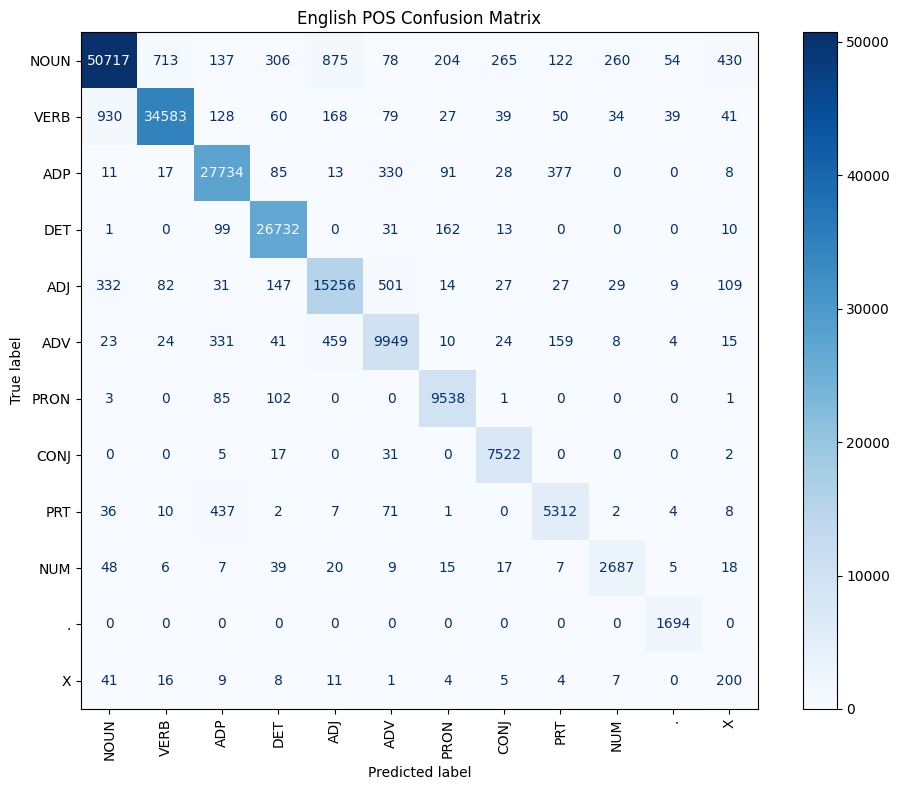

Saved: results/q1_confusion_matrix_english.png


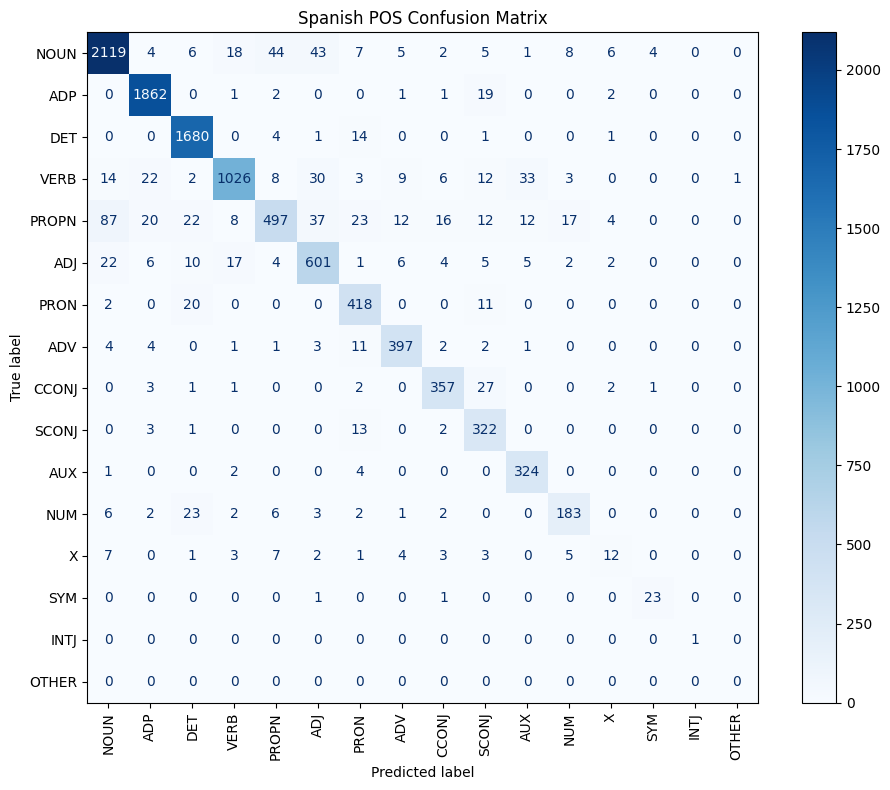

Saved: results/q1_confusion_matrix_spanish.png


In [197]:
def save_confusion_matrix(
    y_true,
    y_pred,
    title,
    filename,
    top_n=15
):

    # Find the most frequent actual tags.
    top_tags = [
        tag
        for tag, _ in
        Counter(y_true).most_common(top_n)
    ]

    # Keep only examples whose actual tag
    # belongs to the selected set.
    filtered_true = []
    filtered_pred = []

    for true_tag, pred_tag in zip(
        y_true,
        y_pred
    ):

        if true_tag in top_tags:

            filtered_true.append(
                true_tag
            )

            filtered_pred.append(
                pred_tag
                if pred_tag in top_tags
                else "OTHER"
            )

    labels = list(top_tags)

    if "OTHER" in filtered_pred:
        labels.append("OTHER")

    cm = confusion_matrix(
        filtered_true,
        filtered_pred,
        labels=labels
    )

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        xticks_rotation=90,
        cmap="Blues",
        colorbar=True
    )

    ax.set_title(title)

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "Saved:",
        filename
    )


os.makedirs(
    "results",
    exist_ok=True
)


save_confusion_matrix(
    en_true,
    en_pred,
    "English POS Confusion Matrix",
    "results/q1_confusion_matrix_english.png"
)


save_confusion_matrix(
    es_true,
    es_pred,
    "Spanish POS Confusion Matrix",
    "results/q1_confusion_matrix_spanish.png"
)

In [198]:
def error_source_summary(result):
    segmentation_errors = (
        result[
            "segmentation_caused_errors"
        ]
    )

    tagging_errors = (
        result[
            "genuine_tagging_errors"
        ]
    )

    total_errors = (
        result["total_errors"]
    )

    segmentation_percentage = (
        100 * segmentation_errors
        / total_errors
        if total_errors
        else 0
    )

    tagging_percentage = (
        100 * tagging_errors
        / total_errors
        if total_errors
        else 0
    )

    return {
        "segmentation_caused": (
            segmentation_errors
        ),
        "genuine_tagging": (
            tagging_errors
        ),
        "total_errors": (
            total_errors
        ),
        "segmentation_error_percent": (
            segmentation_percentage
        ),
        "tagging_error_percent": (
            tagging_percentage
        )
    }


print(
    "English error-source breakdown:"
)

print(
    error_source_summary(
        en_pipeline
    )
)


print(
    "\nSpanish error-source breakdown:"
)

print(
    error_source_summary(
        es_pipeline
    )
)

English error-source breakdown:
{'segmentation_caused': 25301, 'genuine_tagging': 5672, 'total_errors': 30973, 'segmentation_error_percent': 81.68727601459335, 'tagging_error_percent': 18.312723985406645}

Spanish error-source breakdown:
{'segmentation_caused': 1442, 'genuine_tagging': 459, 'total_errors': 1901, 'segmentation_error_percent': 75.85481325618096, 'tagging_error_percent': 24.145186743819043}


In [199]:
def morphology_feature_accuracy(
    tagger,
    dataset
):
    """
    Measures gender and number accuracy
    independently for Spanish tokens where
    those features are present in the gold data.
    """

    gender_correct = 0
    gender_total = 0

    number_correct = 0
    number_total = 0

    for sent in dataset:

        words = [
            item[0]
            for item in sent
        ]

        predicted_tags = tagger.tag(
            words
        )

        for item, predicted_tag in zip(
            sent,
            predicted_tags
        ):

            _, _, gold_gender, gold_number = (
                item
            )

            # Extract the predicted morphology.
            predicted_gender = None
            predicted_number = None

            parts = predicted_tag.split("-")

            if len(parts) >= 2:
                for part in parts[1:]:

                    if part in {
                        "Fem",
                        "Masc"
                    }:
                        predicted_gender = part

                    if part in {
                        "Sing",
                        "Plur"
                    }:
                        predicted_number = part

            if gold_gender:

                gender_total += 1

                if predicted_gender == gold_gender:
                    gender_correct += 1

            if gold_number:

                number_total += 1

                if predicted_number == gold_number:
                    number_correct += 1

    gender_accuracy = (
        gender_correct / gender_total
        if gender_total
        else 0
    )

    number_accuracy = (
        number_correct / number_total
        if number_total
        else 0
    )

    return (
        gender_accuracy,
        number_accuracy
    )


gender_acc, number_acc = (
    morphology_feature_accuracy(
        hmm_es_morph,
        es_test
    )
)

print(
    f"Spanish gender accuracy: "
    f"{gender_acc:.4%}"
)

print(
    f"Spanish number accuracy: "
    f"{number_acc:.4%}"
)

print(
    f"\nExact morphology-aware tag accuracy: "
    f"{es_morph_acc:.4%}"
)

print(
    f"Plain POS accuracy: "
    f"{es_acc:.4%}"
)

Spanish gender accuracy: 95.3457%
Spanish number accuracy: 95.5007%

Exact morphology-aware tag accuracy: 89.1146%
Plain POS accuracy: 91.5471%


In [200]:
sample_cases = [
    (
        "English",
        "thequickbrownfoxjumpsoverthelazydog",
        lm_en,
        hmm_en
    ),

    (
        "Spanish",
        "mispadrespuedenviajar",
        lm_es,
        hmm_es
    ),

    (
        "Spanish",
        "elcielodespejadoesazul",
        lm_es,
        hmm_es
    ),

    (
        "Spanish",
        "lacasarojaesgrande",
        lm_es,
        hmm_es
    )
]


print("========== FINAL SAMPLE OUTPUTS ==========")

for language, text, lm, tagger in sample_cases:

    words = lm.segment(text)

    tags = tagger.tag(words)

    if language == "Spanish":
        tags = normalize_spanish_assignment_tags(
        words,
        tags
    )

    print(
        f"\n[{language}]"
    )

    print(
        "Input:",
        text
    )

    print(
        "Segmentation:",
        " | ".join(words)
    )

    print(
        "POS:",
        " | ".join(
            f"{w}/{t}"
            for w, t in zip(words, tags)
        )
    )

========== FINAL SAMPLE OUTPUTS ==========

[English]
Input: thequickbrownfoxjumpsoverthelazydog
Segmentation: the | quick | brown | fox | jumps | over | the | lazy | dog
POS: the/DET | quick/ADJ | brown/ADJ | fox/NOUN | jumps/VERB | over/ADP | the/DET | lazy/ADJ | dog/NOUN

[Spanish]
Input: mispadrespuedenviajar
Segmentation: mis | padres | pueden | viajar
POS: mis/DET | padres/NOUN | pueden/VERB | viajar/VERB

[Spanish]
Input: elcielodespejadoesazul
Segmentation: el | cielo | des | pe | j | ado | es | azul
POS: el/DET | cielo/NOUN | des/X | pe/PROPN | j/X | ado/PROPN | es/AUX | azul/ADJ

[Spanish]
Input: lacasarojaesgrande
Segmentation: la | casa | roja | es | grande
POS: la/DET | casa/NOUN | roja/ADJ | es/AUX | grande/ADJ


In [201]:
results_table = pd.DataFrame([
    {
        "Language": "English",
        "POS Model": "Trigram HMM",
        "Accuracy": en_acc
    },

    {
        "Language": "English",
        "POS Model": "Most-Frequent-Tag Baseline",
        "Accuracy": en_base_acc
    },

    {
        "Language": "Spanish",
        "POS Model": "Trigram HMM",
        "Accuracy": es_acc
    },

    {
        "Language": "Spanish",
        "POS Model": "Most-Frequent-Tag Baseline",
        "Accuracy": es_base_acc
    },

    {
        "Language": "Spanish",
        "POS Model": "Morphology-Aware HMM",
        "Accuracy": es_morph_acc
    },

    {
        "Language": "Spanish",
        "POS Model": "Morphology-Aware Baseline",
        "Accuracy": es_morph_base_acc
    }
])

results_table["Accuracy"] = (
    results_table["Accuracy"] * 100
).round(2)

results_table

,Language,POS Model,Accuracy
0,English,Trigram HMM,95.12
1,English,Most-Frequent-Tag Baseline,93.73
2,Spanish,Trigram HMM,91.55
3,Spanish,Most-Frequent-Tag Baseline,88.60
4,Spanish,Morphology-Aware HMM,89.11
5,Spanish,Morphology-Aware Baseline,85.38


In [202]:
# Save accuracy/results text file.

with open(
    "results/q1_accuracy_results.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "QUESTION 1 — RESULTS\n"
    )

    f.write(
        "====================\n\n"
    )

    f.write(
        f"English HMM POS accuracy: "
        f"{en_acc:.4%}\n"
    )

    f.write(
        f"English baseline accuracy: "
        f"{en_base_acc:.4%}\n\n"
    )

    f.write(
        f"Spanish HMM POS accuracy: "
        f"{es_acc:.4%}\n"
    )

    f.write(
        f"Spanish baseline accuracy: "
        f"{es_base_acc:.4%}\n"
    )

    f.write(
        f"Spanish morphology-aware HMM: "
        f"{es_morph_acc:.4%}\n"
    )

    f.write(
        f"Spanish morphology-aware baseline: "
        f"{es_morph_base_acc:.4%}\n\n"
    )

    f.write(
        "English segmentation + tagging:\n"
    )

    f.write(
        str(en_pipeline)
        + "\n\n"
    )

    f.write(
        "English greedy baseline:\n"
    )

    f.write(
        str(en_greedy_pipeline)
        + "\n\n"
    )

    f.write(
        "Spanish segmentation + tagging:\n"
    )

    f.write(
        str(es_pipeline)
        + "\n\n"
    )

    f.write(
        "Spanish greedy baseline:\n"
    )

    f.write(
        str(es_greedy_pipeline)
        + "\n\n"
    )

    f.write(
        "Spanish gender accuracy: "
        f"{gender_acc:.4%}\n"
    )

    f.write(
        "Spanish number accuracy: "
        f"{number_acc:.4%}\n"
    )


# Save sample outputs.

with open(
    "results/q1_sample_outputs.txt",
    "w",
    encoding="utf-8"
) as f:

    for language, text, lm, tagger in sample_cases:

        words = lm.segment(text)

        tags = tagger.tag(words)

        if language == "Spanish":
             tags = normalize_spanish_assignment_tags(
             words,
             tags
        )

        f.write(
            f"[{language}]\n"
        )

        f.write(
            f"Input: {text}\n"
        )

        f.write(
            "Segmentation: "
            + " | ".join(words)
            + "\n"
        )

        f.write(
            "POS: "
            + " | ".join(
                f"{w}/{t}"
                for w, t
                in zip(words, tags)
            )
            + "\n\n"
        )


print(
    "Q1 result files saved in results/"
)

Q1 result files saved in results/


In [203]:
import cloudpickle
import os

q1_model_bundle = {
    "lm_en": lm_en,
    "hmm_en": hmm_en,
    "vocab_en": vocab_en,

    "settings": {
        "max_word_len": lm_en.max_word_len,
        "lambda3": lm_en.lambda3,
        "lambda2": lm_en.lambda2,
        "lambda1": lm_en.lambda1,
        "lambda0": lm_en.lambda0,
        "word_penalty": lm_en.word_penalty
    }
}

q1_model_path = os.path.join(
    MODEL_DIR,
    "q1_models.pkl"
)

with open(
    q1_model_path,
    "wb"
) as f:

    cloudpickle.dump(
        q1_model_bundle,
        f
    )

print("Q1 models saved successfully!")
print("Location:")
print(q1_model_path)

print(
    "\nFile exists:",
    os.path.exists(q1_model_path)
)

Q1 models saved successfully!
Location:
/content/drive/MyDrive/GROUP_ASSIGNMENT_1/models/q1_models.pkl

File exists: True


In [204]:
print("Files created:")

for root, dirs, files in os.walk("."):

    for filename in files:

        if (
            filename.endswith(".png")
            or filename.endswith(".txt")
            or filename.endswith(".pkl")
        ):

            print(
                os.path.join(root, filename)
            )

Files created:
./results/q1_confusion_matrix_english.png
./results/q1_confusion_matrix_spanish.png
./results/q1_sample_outputs.txt
./results/q1_accuracy_results.txt
./drive/MyDrive/GROUP_ASSIGNMENT_1/models/q1_models.pkl
./drive/MyDrive/GROUP_ASSIGNMENT_1/models/q3_models.pkl
./drive/MyDrive/GROUP_ASSIGNMENT_1/Q1/q1_results.txt
./UD_Spanish-GSD/LICENSE.txt
